In [3]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [1]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm import tqdm

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
c:\Users\admin\Desktop\SignBridge\.venv\Scripts\python.exe


In [3]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

print("All libraries imported successfully!")
print("MediaPipe version:", mp.__version__)

All libraries imported successfully!
MediaPipe version: 1.2.3


In [6]:
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe Tasks imported successfully!")

MediaPipe Tasks imported successfully!


In [7]:
model_path = "../models/hand_landmarker.task"

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5
)

detector = vision.HandLandmarker.create_from_options(options)

print("Hand Landmarker initialized successfully!")

Hand Landmarker initialized successfully!


In [14]:
from pathlib import Path

PROJECT_PATH = Path(r"C:\Users\admin\Desktop\SignBridge")

ISL_PATH = PROJECT_PATH / "data" / "raw" / "ISL" / "ISL_Image_Dataset"

ASL_PATH = PROJECT_PATH / "data" / "raw" / "ASL" / "ASL_Image_Dataset"

print("ISL folder exists:", ISL_PATH.exists())
print("ASL folder exists:", ASL_PATH.exists())

print("ISL path:", ISL_PATH)
print("ASL path:", ASL_PATH)

ISL folder exists: True
ASL folder exists: True
ISL path: C:\Users\admin\Desktop\SignBridge\data\raw\ISL\ISL_Image_Dataset
ASL path: C:\Users\admin\Desktop\SignBridge\data\raw\ASL\ASL_Image_Dataset


In [15]:
sample_folder = next(
    folder for folder in ISL_PATH.iterdir()
    if folder.is_dir()
)

sample_image_path = next(
    file for file in sample_folder.iterdir()
    if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
)

image = cv2.imread(str(sample_image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

results = detector.detect(mp_image)

if results.hand_landmarks:
    print("Hand detected!")
    print("Number of hands:", len(results.hand_landmarks))
    print("Landmarks on first hand:", len(results.hand_landmarks[0]))
else:
    print("No hand detected.")

StopIteration: 

In [16]:
print("ISL dataset path:", ISL_PATH)

for folder in sorted(ISL_PATH.iterdir())[:5]:
    print(f"\nFolder: {folder.name}")
    
    if folder.is_dir():
        for item in list(folder.iterdir())[:5]:
            print("  ", item.name)

ISL dataset path: C:\Users\admin\Desktop\SignBridge\data\raw\ISL\ISL_Image_Dataset

Folder: data
   1
   2
   3
   4
   5


In [17]:
image_extensions = [
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
]

isl_images = [
    file for file in ISL_PATH.rglob("*")
    if file.is_file()
    and file.suffix.lower() in image_extensions
]

print("Total images found:", len(isl_images))

if isl_images:
    print("\nFirst image:", isl_images[0])
else:
    print("No images found.")

Total images found: 42000

First image: C:\Users\admin\Desktop\SignBridge\data\raw\ISL\ISL_Image_Dataset\data\1\0.jpg


In [18]:
sample_image_path = isl_images[0]

image = cv2.imread(str(sample_image_path))

if image is None:
    print("Could not read image.")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    results = detector.detect(mp_image)

    print("Image loaded:", image.shape)

    if results.hand_landmarks:
        print("Hand detected!")
        print("Number of hands:", len(results.hand_landmarks))
        print("Landmarks:", len(results.hand_landmarks[0]))
    else:
        print("No hand detected in this image.")

Image loaded: (128, 128, 3)
Hand detected!
Number of hands: 1
Landmarks: 21


In [19]:
def extract_hand_features(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    results = detector.detect(mp_image)

    if not results.hand_landmarks:
        return None

    # Use the first detected hand
    landmarks = results.hand_landmarks[0]

    coordinates = np.array([
        [lm.x, lm.y, lm.z]
        for lm in landmarks
    ])

    # Normalize relative to wrist
    coordinates = coordinates - coordinates[0]

    # Normalize by hand scale
    scale = np.max(np.linalg.norm(coordinates[:, :2], axis=1))

    if scale > 0:
        coordinates = coordinates / scale

    return coordinates.flatten()

In [20]:
features = extract_hand_features(sample_image_path)

if features is not None:
    print("Feature extraction successful!")
    print("Number of features:", len(features))
    print("Sample values:", features[:10])
else:
    print("No hand detected.")

Feature extraction successful!
Number of features: 63
Sample values: [ 0.          0.          0.         -0.10767909 -0.12217915 -0.08452086
 -0.15839214 -0.27809594 -0.15223689 -0.08365812]


In [22]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


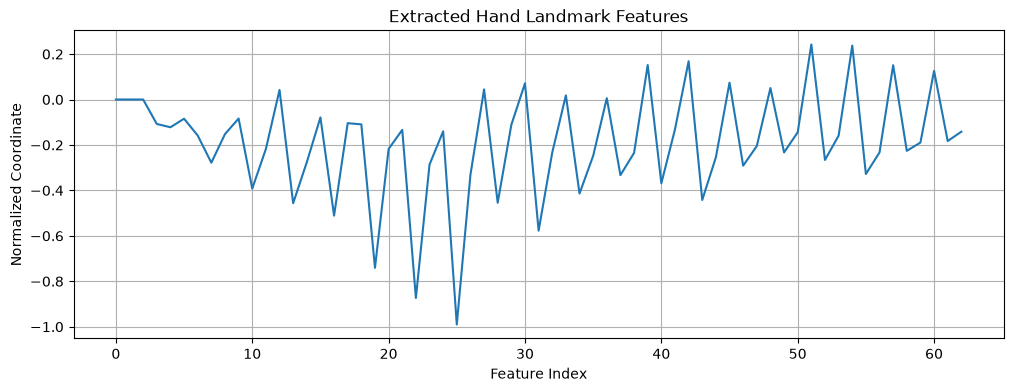

In [23]:
plt.figure(figsize=(12, 4))

plt.plot(features)

plt.title("Extracted Hand Landmark Features")
plt.xlabel("Feature Index")
plt.ylabel("Normalized Coordinate")

plt.grid()
plt.show()

In [24]:
print("Number of features:", len(features))
print("Feature values:", features[:10])

Number of features: 63
Feature values: [ 0.          0.          0.         -0.10767909 -0.12217915 -0.08452086
 -0.15839214 -0.27809594 -0.15223689 -0.08365812]


In [26]:
ISL_CLASS_ROOT = ISL_PATH / "data"

print("Class folders:")

for folder in sorted(ISL_CLASS_ROOT.iterdir()):
    if folder.is_dir():
        print(folder.name)

Class folders:
1
2
3
4
5
6
7
8
9
A
B
C
D
E
F
G
H
I
J
K
L
M
N
O
P
Q
R
S
T
U
V
W
X
Y
Z


In [27]:
from tqdm import tqdm

image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

test_images = [
    file for file in ISL_CLASS_ROOT.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
][:100]

successful = 0
failed = 0

for image_path in tqdm(test_images):
    result = extract_hand_features(image_path)

    if result is not None:
        successful += 1
    else:
        failed += 1

print("Total tested:", len(test_images))
print("Successful detections:", successful)
print("Failed detections:", failed)

100%|██████████| 100/100 [00:07<00:00, 13.68it/s]

Total tested: 100
Successful detections: 100
Failed detections: 0


In [29]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\admin\Desktop\SignBridge


In [30]:
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

print("Output folder:", PROCESSED_PATH)

Output folder: c:\Users\admin\Desktop\SignBridge\data\processed


In [31]:
import pandas as pd
from tqdm import tqdm

isl_records = []

class_folders = sorted(
    folder for folder in ISL_CLASS_ROOT.iterdir()
    if folder.is_dir()
)

for class_folder in class_folders:

    label = class_folder.name

    image_files = [
        file for file in class_folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    for image_path in tqdm(image_files, desc=f"Processing {label}"):

        extracted_features = extract_hand_features(image_path)

        if extracted_features is not None:

            record = {
                "label": label,
                "image_path": str(image_path.relative_to(PROJECT_ROOT))
            }

            for i, value in enumerate(extracted_features):
                record[f"feature_{i}"] = value

            isl_records.append(record)

print("Extraction completed!")
print("Total successful images:", len(isl_records))

Processing Z: 100%|██████████| 1200/1200 [01:42<00:00, 11.76it/s]

Extraction completed!
Total successful images: 41164


In [32]:
isl_df = pd.DataFrame(isl_records)

isl_csv_path = PROCESSED_PATH / "isl_landmarks.csv"

isl_df.to_csv(isl_csv_path, index=False)

print("CSV saved successfully!")
print("Location:", isl_csv_path)
print("Dataset shape:", isl_df.shape)

isl_df.head()

CSV saved successfully!
Location: c:\Users\admin\Desktop\SignBridge\data\processed\isl_landmarks.csv
Dataset shape: (41164, 65)


,label,image_path,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62
0,1,data\raw\ISL\ISL_Image_Dataset\data\1\0.jpg,0.0,0.0,0.0,-0.107679,-0.122179,-0.084521,-0.158392,-0.278096,...,-0.159088,0.237435,-0.327846,-0.232874,0.150844,-0.225824,-0.189484,0.126100,-0.182830,-0.141681
1,1,data\raw\ISL\ISL_Image_Dataset\data\1\1.jpg,0.0,0.0,0.0,-0.106522,-0.118406,-0.083403,-0.155268,-0.272870,...,-0.162552,0.235255,-0.329100,-0.234757,0.151324,-0.227397,-0.189414,0.129587,-0.185663,-0.139914
2,1,data\raw\ISL\ISL_Image_Dataset\data\1\10.jpg,0.0,0.0,0.0,-0.109189,-0.120111,-0.080310,-0.159281,-0.275953,...,-0.157011,0.237460,-0.326929,-0.229576,0.152466,-0.226034,-0.186223,0.124118,-0.182281,-0.137511
3,1,data\raw\ISL\ISL_Image_Dataset\data\1\100.jpg,0.0,0.0,0.0,-0.099648,-0.127929,-0.086190,-0.157674,-0.290140,...,-0.162330,0.248721,-0.337684,-0.239470,0.158562,-0.238558,-0.194940,0.136522,-0.186517,-0.143611
4,1,data\raw\ISL\ISL_Image_Dataset\data\1\1000.jpg,0.0,0.0,0.0,-0.089180,-0.119581,-0.113504,-0.119633,-0.278801,...,-0.137841,0.283054,-0.311712,-0.221353,0.191959,-0.213302,-0.182896,0.152751,-0.174872,-0.135481


In [33]:
print("ASL path:", ASL_PATH)

for item in ASL_PATH.iterdir():
    print(item.name, "->", "Folder" if item.is_dir() else "File")

ASL path: C:\Users\admin\Desktop\SignBridge\data\raw\ASL\ASL_Image_Dataset
American -> Folder


In [34]:
asl_images = [
    file for file in ASL_PATH.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("Total ASL images:", len(asl_images))

if asl_images:
    print("First ASL image:", asl_images[0])

Total ASL images: 142261
First ASL image: C:\Users\admin\Desktop\SignBridge\data\raw\ASL\ASL_Image_Dataset\American\0\1 copy.jpg


In [35]:
ASL_CLASS_ROOT = ASL_PATH / "American"

print("ASL class folders:")

for folder in sorted(ASL_CLASS_ROOT.iterdir()):
    if folder.is_dir():
        print(folder.name)

ASL class folders:
0
1
2
3
4
5
6
7
8
9
a
b
c
d
e
f
g
h
i
j
k
l
m
n
o
p
q
r
s
t
u
v
w
x
y
z


In [36]:
asl_test_images = [
    file for file in ASL_CLASS_ROOT.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
][:100]

successful = 0
failed = 0

for image_path in tqdm(asl_test_images):
    result = extract_hand_features(image_path)

    if result is not None:
        successful += 1
    else:
        failed += 1

print("Total tested:", len(asl_test_images))
print("Successful detections:", successful)
print("Failed detections:", failed)

100%|██████████| 100/100 [00:03<00:00, 25.68it/s]

Total tested: 100
Successful detections: 0
Failed detections: 100


Image path: C:\Users\admin\Desktop\SignBridge\data\raw\ASL\ASL_Image_Dataset\American\0\1 copy.jpg
Image shape: (50, 50, 3)


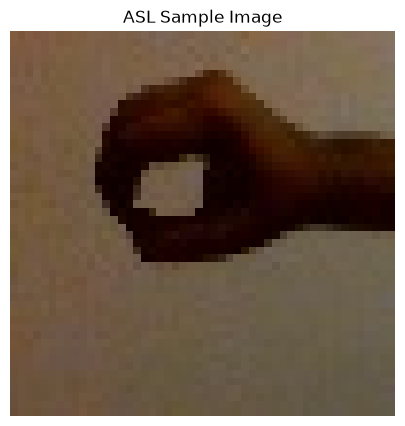

In [37]:
import matplotlib.pyplot as plt
import cv2

sample_path = asl_test_images[0]

image = cv2.imread(str(sample_path))

print("Image path:", sample_path)
print("Image shape:", image.shape if image is not None else "Failed to load")

if image is not None:
    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("ASL Sample Image")
    plt.axis("off")
    plt.show()

In [38]:
from PIL import Image

sample_path = asl_test_images[0]

img = Image.open(sample_path)

print("Image dimensions:", img.size)
print("Image format:", img.format)
print("Image mode:", img.mode)

Image dimensions: (50, 50)
Image format: JPEG
Image mode: RGB


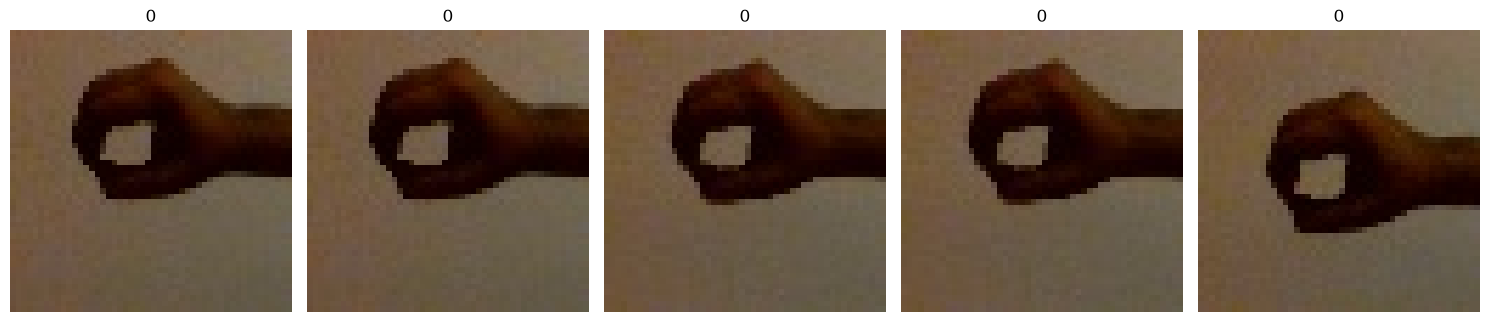

In [39]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, path in zip(axes, asl_test_images[:5]):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(path.parent.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\admin\Desktop\SignBridge


In [40]:
from PIL import Image

sample_path = asl_test_images[0]

img = Image.open(sample_path)

print("Dimensions:", img.size)
print("Format:", img.format)
print("Colour mode:", img.mode)

Dimensions: (50, 50)
Format: JPEG
Colour mode: RGB


In [42]:
options_test = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path=str(model_path)
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.2,
    min_hand_presence_confidence=0.2
)

asl_test_detector = vision.HandLandmarker.create_from_options(options_test)

print("ASL test detector initialized!")

ASL test detector initialized!


In [43]:
image = cv2.imread(str(sample_path))

resized_image = cv2.resize(
    image,
    (256, 256),
    interpolation=cv2.INTER_CUBIC
)

image_rgb = cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)

results = asl_test_detector.detect(mp_image)

print("Hands detected after resizing:", len(results.hand_landmarks))

Hands detected after resizing: 1


In [45]:
asl_pilot_images = []

for class_folder in sorted(ASL_CLASS_ROOT.iterdir()):

    if class_folder.is_dir():

        images = [
            p for p in class_folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        ]

        asl_pilot_images.extend(images[:5])

print("Total pilot images:", len(asl_pilot_images))

successful = 0
failed = 0

for image_path in tqdm(asl_pilot_images):

    image = cv2.imread(str(image_path))

    if image is None:
        failed += 1
        continue

    resized_image = cv2.resize(
        image,
        (256, 256),
        interpolation=cv2.INTER_CUBIC
    )

    image_rgb = cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    results = asl_test_detector.detect(mp_image)

    if results.hand_landmarks:
        successful += 1
    else:
        failed += 1

print("\nASL PILOT RESULTS")
print("Total tested:", len(asl_pilot_images))
print("Successful:", successful)
print("Failed:", failed)
print("Detection rate:", round(successful / len(asl_pilot_images) * 100, 2), "%")

Total pilot images: 180


100%|██████████| 180/180 [00:10<00:00, 16.46it/s]


ASL PILOT RESULTS
Total tested: 180
Successful: 116
Failed: 64
Detection rate: 64.44 %


In [46]:
asl_class_results = []

for class_folder in sorted(ASL_CLASS_ROOT.iterdir()):

    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ][:5]

    success = 0
    failure = 0

    for image_path in images:

        image = cv2.imread(str(image_path))

        if image is None:
            failure += 1
            continue

        resized = cv2.resize(
            image,
            (256, 256),
            interpolation=cv2.INTER_CUBIC
        )

        rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        result = asl_test_detector.detect(mp_image)

        if result.hand_landmarks:
            success += 1
        else:
            failure += 1

    asl_class_results.append({
        "Class": class_folder.name,
        "Successful": success,
        "Failed": failure,
        "Detection Rate (%)": round(success / len(images) * 100, 2)
    })

asl_results_df = pd.DataFrame(asl_class_results)

asl_results_df

,Class,Successful,Failed,Detection Rate (%)
0,0,2,3,40.0
1,1,3,2,60.0
2,2,1,4,20.0
3,3,0,5,0.0
4,4,2,3,40.0
5,5,2,3,40.0
6,6,2,3,40.0
7,7,0,5,0.0
8,8,2,3,40.0
9,9,0,5,0.0


In [47]:
from collections import Counter

dimension_counts = Counter()

for path in asl_images:
    try:
        with Image.open(path) as img:
            dimension_counts[img.size] += 1
    except Exception:
        continue

for dimensions, count in dimension_counts.most_common(10):
    print(dimensions, ":", count)

(200, 200) : 77891
(50, 50) : 61500
(400, 400) : 2870


In [ ]:
import random
from PIL import Image

random.seed(42)

resolution_groups = {
    (50, 50): [],
    (200, 200): [],
    (400, 400): []
}

for path in asl_images:
    try:
        with Image.open(path) as img:
            if img.size in resolution_groups:
                resolution_groups[img.size].append(path)
    except Exception:
        continue

for resolution, paths in resolution_groups.items():
    print(resolution, ":", len(paths), "images")

    

(50, 50) : 61500 images
(200, 200) : 77891 images
(400, 400) : 2870 images


In [49]:
resolution_results = []

for resolution, paths in resolution_groups.items():

    sample = random.sample(paths, min(100, len(paths)))

    successful = 0

    for path in tqdm(sample, desc=str(resolution)):

        image = cv2.imread(str(path))

        if image is None:
            continue

        if resolution == (50, 50):
            image = cv2.resize(
                image,
                (256, 256),
                interpolation=cv2.INTER_CUBIC
            )

        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        result = asl_test_detector.detect(mp_image)

        if result.hand_landmarks:
            successful += 1

    rate = successful / len(sample) * 100

    resolution_results.append({
        "Resolution": str(resolution),
        "Tested": len(sample),
        "Successful": successful,
        "Failed": len(sample) - successful,
        "Detection Rate (%)": round(rate, 2)
    })

pd.DataFrame(resolution_results)

(400, 400): 100%|██████████| 100/100 [00:05<00:00, 17.27it/s]


,Resolution,Tested,Successful,Failed,Detection Rate (%)
0,"(50, 50)",100,53,47,53.0
1,"(200, 200)",100,86,14,86.0
2,"(400, 400)",100,81,19,81.0


In [50]:
from collections import defaultdict
from PIL import Image

class_resolution_counts = defaultdict(lambda: {
    "50x50": 0,
    "200x200": 0,
    "400x400": 0
})

for path in tqdm(asl_images):

    try:
        with Image.open(path) as img:
            resolution = img.size

        label = path.parent.name

        if resolution == (50, 50):
            class_resolution_counts[label]["50x50"] += 1

        elif resolution == (200, 200):
            class_resolution_counts[label]["200x200"] += 1

        elif resolution == (400, 400):
            class_resolution_counts[label]["400x400"] += 1

    except Exception:
        continue

resolution_df = pd.DataFrame.from_dict(
    class_resolution_counts,
    orient="index"
)

resolution_df.index.name = "Class"

resolution_df["Usable Images"] = (
    resolution_df["200x200"] + resolution_df["400x400"]
)

resolution_df

100%|██████████| 142261/142261 [03:34<00:00, 662.15it/s] 


,50x50,200x200,400x400,Usable Images
Class,,,,
0,3000,0,70,70
1,1500,0,70,70
2,1500,0,70,70
3,1500,0,70,70
4,3000,0,70,70
5,3000,0,70,70
6,3000,0,70,70
7,3000,0,70,70
8,3000,0,70,70


In [51]:
from PIL import Image
from collections import defaultdict
from tqdm import tqdm

asl_usable_counts = defaultdict(int)

for path in tqdm(asl_images):
    try:
        with Image.open(path) as img:
            if img.size in [(200, 200), (400, 400)]:
                asl_usable_counts[path.parent.name] += 1
    except Exception:
        continue

for label in sorted(asl_usable_counts):
    print(label, ":", asl_usable_counts[label])

100%|██████████| 142261/142261 [02:10<00:00, 1088.11it/s]

0 : 70
1 : 70
2 : 70
3 : 70
4 : 70
5 : 70
6 : 70
7 : 70
8 : 70
9 : 70
a : 3070
b : 3070
c : 3070
d : 3070
e : 3070
f : 3070
g : 3070
h : 3070
i : 3807
j : 3124
k : 2488
l : 3494
m : 2924
n : 3968
o : 4294
p : 2566
q : 3590
r : 3538
s : 2374
t : 3076
u : 3244
v : 3926
w : 2086
x : 2330
y : 2454
z : 2218


In [53]:
def extract_hand_features_asl(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image_rgb
    )

    results = asl_test_detector.detect(mp_image)

    if not results.hand_landmarks:
        return None

    landmarks = results.hand_landmarks[0]

    coordinates = np.array([
        [lm.x, lm.y, lm.z]
        for lm in landmarks
    ])

    # Normalize coordinates relative to wrist
    coordinates = coordinates - coordinates[0]

    # Scale normalization
    scale = np.max(
        np.linalg.norm(coordinates[:, :2], axis=1)
    )

    if scale > 0:
        coordinates = coordinates / scale

    return coordinates.flatten()

In [54]:
test_asl_features = extract_hand_features_asl(asl_images[0])

if test_asl_features is not None:
    print("ASL feature extraction successful!")
    print("Number of features:", len(test_asl_features))
else:
    print("No hand detected in this image.")

ASL feature extraction successful!
Number of features: 63


In [55]:
import random
from tqdm import tqdm

random.seed(42)

asl_records = []

ASL_CLASS_ROOT = ASL_PATH / "American"

for class_folder in sorted(ASL_CLASS_ROOT.iterdir()):

    if not class_folder.is_dir():
        continue

    label = class_folder.name

    usable_images = []

    for path in class_folder.iterdir():
        if path.suffix.lower() not in image_extensions:
            continue

        try:
            image = cv2.imread(str(path))

            if image is None:
                continue

            height, width = image.shape[:2]

            if (width, height) in [(200, 200), (400, 400)]:
                usable_images.append(path)

        except Exception:
            continue

    selected_images = random.sample(usable_images, 70)

    print(f"Class {label}: selected {len(selected_images)} images")

    for image_path in tqdm(selected_images, desc=f"Processing {label}"):

        features = extract_hand_features_asl(image_path)

        if features is not None:
            record = {
                "label": label,
                "image_path": str(image_path)
            }

            for i, value in enumerate(features):
                record[f"feature_{i}"] = value

            asl_records.append(record)

print("\nASL extraction completed!")
print("Total successful images:", len(asl_records))

Class 0: selected 70 images


Processing 0: 100%|██████████| 70/70 [00:04<00:00, 14.86it/s]


Class 1: selected 70 images


Processing 1: 100%|██████████| 70/70 [00:05<00:00, 13.40it/s]


Class 2: selected 70 images


Processing 2: 100%|██████████| 70/70 [00:05<00:00, 13.41it/s]


... (63 outputs left out)

Processing y: 100%|██████████| 70/70 [00:04<00:00, 14.78it/s]


Class z: selected 70 images


Processing z: 100%|██████████| 70/70 [00:04<00:00, 15.51it/s]


ASL extraction completed!
Total successful images: 2118


In [56]:
asl_df = pd.DataFrame(asl_records)

asl_class_counts = asl_df["label"].value_counts().sort_index()

print("Total extracted images:", len(asl_df))
print("Number of classes:", asl_df["label"].nunique())

print("\nSuccessful images per class:")
print(asl_class_counts)

print("\nClasses with fewer than 40 images:")
print(asl_class_counts[asl_class_counts < 40])

Total extracted images: 2118
Number of classes: 36

Successful images per class:
label
0    43
1    66
2    62
3    70
4    70
5    70
6    62
7    67
8    64
9    70
a    55
b    55
c    52
d    66
e    55
f    70
g    60
h    60
i    63
j    67
k    67
l    66
m    55
n    52
o    45
p    44
q    11
r    61
s    59
t    54
u    49
v    58
w    70
x    50
y    65
z    65
Name: count, dtype: int64

Classes with fewer than 40 images:
label
q    11
Name: count, dtype: int64


In [57]:
asl_csv_path = PROCESSED_PATH / "asl_landmarks.csv"

asl_df.to_csv(asl_csv_path, index=False)

print("ASL dataset saved!")
print("Location:", asl_csv_path)
print("Dataset shape:", asl_df.shape)

ASL dataset saved!
Location: c:\Users\admin\Desktop\SignBridge\data\processed\asl_landmarks.csv
Dataset shape: (2118, 65)


In [59]:
q_images = list((ASL_CLASS_ROOT / "q").glob("*"))

print("Total images in q folder:", len(q_images))
print("Image extensions:", 
      Counter(p.suffix.lower() for p in q_images))

Total images in q folder: 3590
Image extensions: Counter({'.jpg': 3520, '.jpeg': 70})


In [60]:
from collections import Counter
from PIL import Image

q_resolution_counts = Counter()

for path in q_images:
    try:
        with Image.open(path) as img:
            q_resolution_counts[img.size] += 1
    except Exception:
        continue

print(q_resolution_counts)

Counter({(200, 200): 3520, (400, 400): 70})


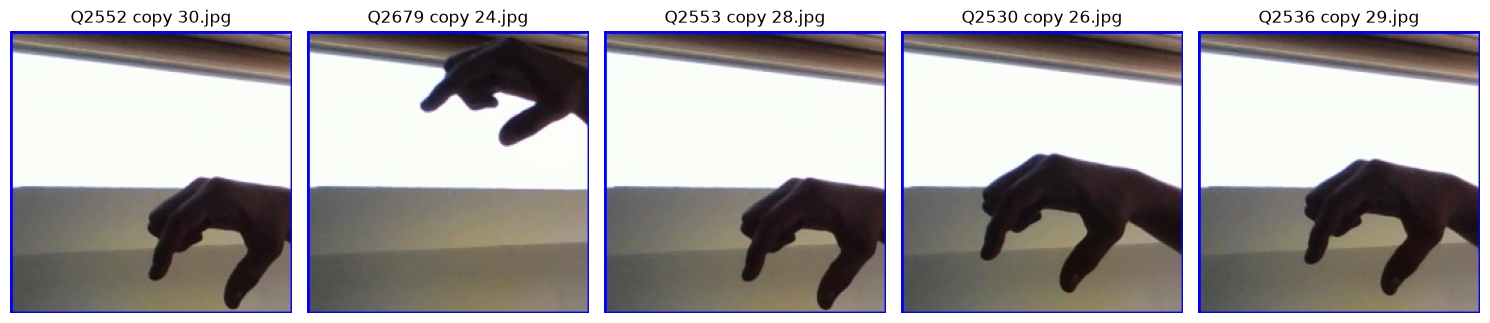

In [61]:
import matplotlib.pyplot as plt
import random

sample_q = random.sample(q_images, 5)

plt.figure(figsize=(15, 4))

for i, path in enumerate(sample_q):
    img = cv2.imread(str(path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [62]:
q_test_images = random.sample(q_images, 20)

q_test_results = []

for path in q_test_images:
    features = extract_hand_features_asl(path)

    q_test_results.append({
        "image": path.name,
        "detected": features is not None
    })

q_test_df = pd.DataFrame(q_test_results)

print(q_test_df)
print("\nDetection rate:",
      q_test_df["detected"].sum(), "/ 20")

                             image  detected
0                Q2576 copy 30.jpg     False
1                Q2566 copy 12.jpg     False
2                Q2689 copy 29.jpg     False
3                Q2584 copy 18.jpg     False
4                 Q2536 copy 3.jpg     False
5                Q2685 copy 10.jpg     False
6                 Q477 copy 24.jpg      True
7                Q2541 copy 22.jpg     False
8   hand1_q_top_seg_2_cropped.jpeg      True
9                Q2594 copy 18.jpg     False
10               Q2544 copy 10.jpg     False
11                Q2575 copy 8.jpg     False
12               Q2681 copy 21.jpg     False
13               Q2584 copy 30.jpg     False
14                Q2584 copy 9.jpg     False
15               Q2681 copy 12.jpg     False
16                Q2549 copy 2.jpg     False
17                Q409 copy 27.jpg      True
18               Q2560 copy 27.jpg     False
19                Q2564 copy 9.jpg     False

Detection rate: 3 / 20


In [63]:
from PIL import Image
import random

q_400 = []
q_200 = []

for path in q_images:
    try:
        with Image.open(path) as img:
            if img.size == (400, 400):
                q_400.append(path)
            elif img.size == (200, 200):
                q_200.append(path)
    except Exception:
        continue

print("400x400 images:", len(q_400))
print("200x200 images:", len(q_200))

400x400 images: 70
200x200 images: 3520


In [64]:
def test_detection(images):
    successful = 0

    for path in tqdm(images):
        features = extract_hand_features_asl(path)

        if features is not None:
            successful += 1

    print("Tested:", len(images))
    print("Detected:", successful)
    print("Failed:", len(images) - successful)
    print("Detection rate:", round(successful / len(images) * 100, 2), "%")


print("400x400 TEST")
test_detection(q_400)

print("\n200x200 TEST")
test_detection(random.sample(q_200, 70))


400x400 TEST


100%|██████████| 70/70 [00:04<00:00, 14.22it/s]


Tested: 70
Detected: 35
Failed: 35
Detection rate: 50.0 %

200x200 TEST


100%|██████████| 70/70 [00:04<00:00, 17.32it/s]

Tested: 70
Detected: 19
Failed: 51
Detection rate: 27.14 %


In [65]:
# Get image paths already extracted for class q
existing_q_paths = set(
    asl_df.loc[asl_df["label"] == "q", "image_path"]
)

# Select additional images
additional_q_images = q_400 + random.sample(q_200, 100)

# Remove previously processed images
additional_q_images = [
    path for path in additional_q_images
    if str(path) not in existing_q_paths
]

print("Additional images to process:", len(additional_q_images))

new_q_records = []

for image_path in tqdm(additional_q_images, desc="Improving class q"):

    features = extract_hand_features_asl(image_path)

    if features is not None:
        record = {
            "label": "q",
            "image_path": str(image_path)
        }

        for i, value in enumerate(features):
            record[f"feature_{i}"] = value

        new_q_records.append(record)

print("\nAdditional successful extractions:", len(new_q_records))

Additional images to process: 169


Improving class q: 100%|██████████| 169/169 [00:10<00:00, 16.40it/s]


Additional successful extractions: 52


In [66]:
if new_q_records:
    asl_df = pd.concat(
        [asl_df, pd.DataFrame(new_q_records)],
        ignore_index=True
    )

asl_class_counts = asl_df["label"].value_counts().sort_index()

print("Updated class q count:", asl_class_counts["q"])
print("\nUpdated total images:", len(asl_df))

Updated class q count: 63

Updated total images: 2170


In [67]:
asl_csv_path = PROCESSED_PATH / "asl_landmarks.csv"

asl_df.to_csv(asl_csv_path, index=False)

print("Updated ASL dataset saved!")
print("Dataset shape:", asl_df.shape)

Updated ASL dataset saved!
Dataset shape: (2170, 65)


In [68]:
asl_class_counts = asl_df["label"].value_counts().sort_index()

print("Total images:", len(asl_df))
print("Total classes:", asl_df["label"].nunique())

print("\nImages per class:")
print(asl_class_counts.to_string())

print("\nClasses with fewer than 40 images:")
print(asl_class_counts[asl_class_counts < 40])

Total images: 2170
Total classes: 36

Images per class:
label
0    43
1    66
2    62
3    70
4    70
5    70
6    62
7    67
8    64
9    70
a    55
b    55
c    52
d    66
e    55
f    70
g    60
h    60
i    63
j    67
k    67
l    66
m    55
n    52
o    45
p    44
q    63
r    61
s    59
t    54
u    49
v    58
w    70
x    50
y    65
z    65

Classes with fewer than 40 images:
Series([], Name: count, dtype: int64)


In [69]:
print("Minimum samples:", asl_class_counts.min())
print("Maximum samples:", asl_class_counts.max())
print("Average samples:", round(asl_class_counts.mean(), 2))

Minimum samples: 43
Maximum samples: 70
Average samples: 60.28


In [70]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Separate features and labels
feature_columns = [
    col for col in asl_df.columns
    if col.startswith("feature_")
]

X = asl_df[feature_columns]
y = asl_df["label"].astype(str)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)
print("Number of classes:", y.nunique())

Feature shape: (2170, 63)
Label shape: (2170,)
Number of classes: 36


In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1736
Testing samples: 434


In [73]:
# Ensure every label is a string
asl_df["label"] = asl_df["label"].astype(str)

feature_columns = [
    col for col in asl_df.columns
    if col.startswith("feature_")
]

X = asl_df[feature_columns].astype(float)
y = asl_df["label"]

print("Label data type:", y.dtype)
print("Classes:", sorted(y.unique()))
print("Number of classes:", y.nunique())

Label data type: str
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
Number of classes: 36


In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1736
Testing samples: 434


In [75]:
asl_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

asl_model.fit(X_train, y_train)

print("ASL Random Forest training completed!")

ASL Random Forest training completed!


In [76]:
y_pred = asl_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("ASL MODEL ACCURACY:", round(accuracy * 100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

ASL MODEL ACCURACY: 94.01 %

Classification Report:

              precision    recall  f1-score   support

           0       0.75      0.67      0.71         9
           1       0.92      0.92      0.92        13
           2       0.92      1.00      0.96        12
           3       1.00      1.00      1.00        14
           4       0.93      0.93      0.93        14
           5       1.00      1.00      1.00        14
           6       0.92      1.00      0.96        12
           7       1.00      1.00      1.00        13
           8       1.00      0.92      0.96        13
           9       1.00      1.00      1.00        14
           a       1.00      1.00      1.00        11
           b       1.00      0.91      0.95        11
           c       0.83      1.00      0.91        10
           d       1.00      1.00      1.00        13
           e       1.00      1.00      1.00        11
           f       1.00      1.00      1.00        14
           g       0.71     

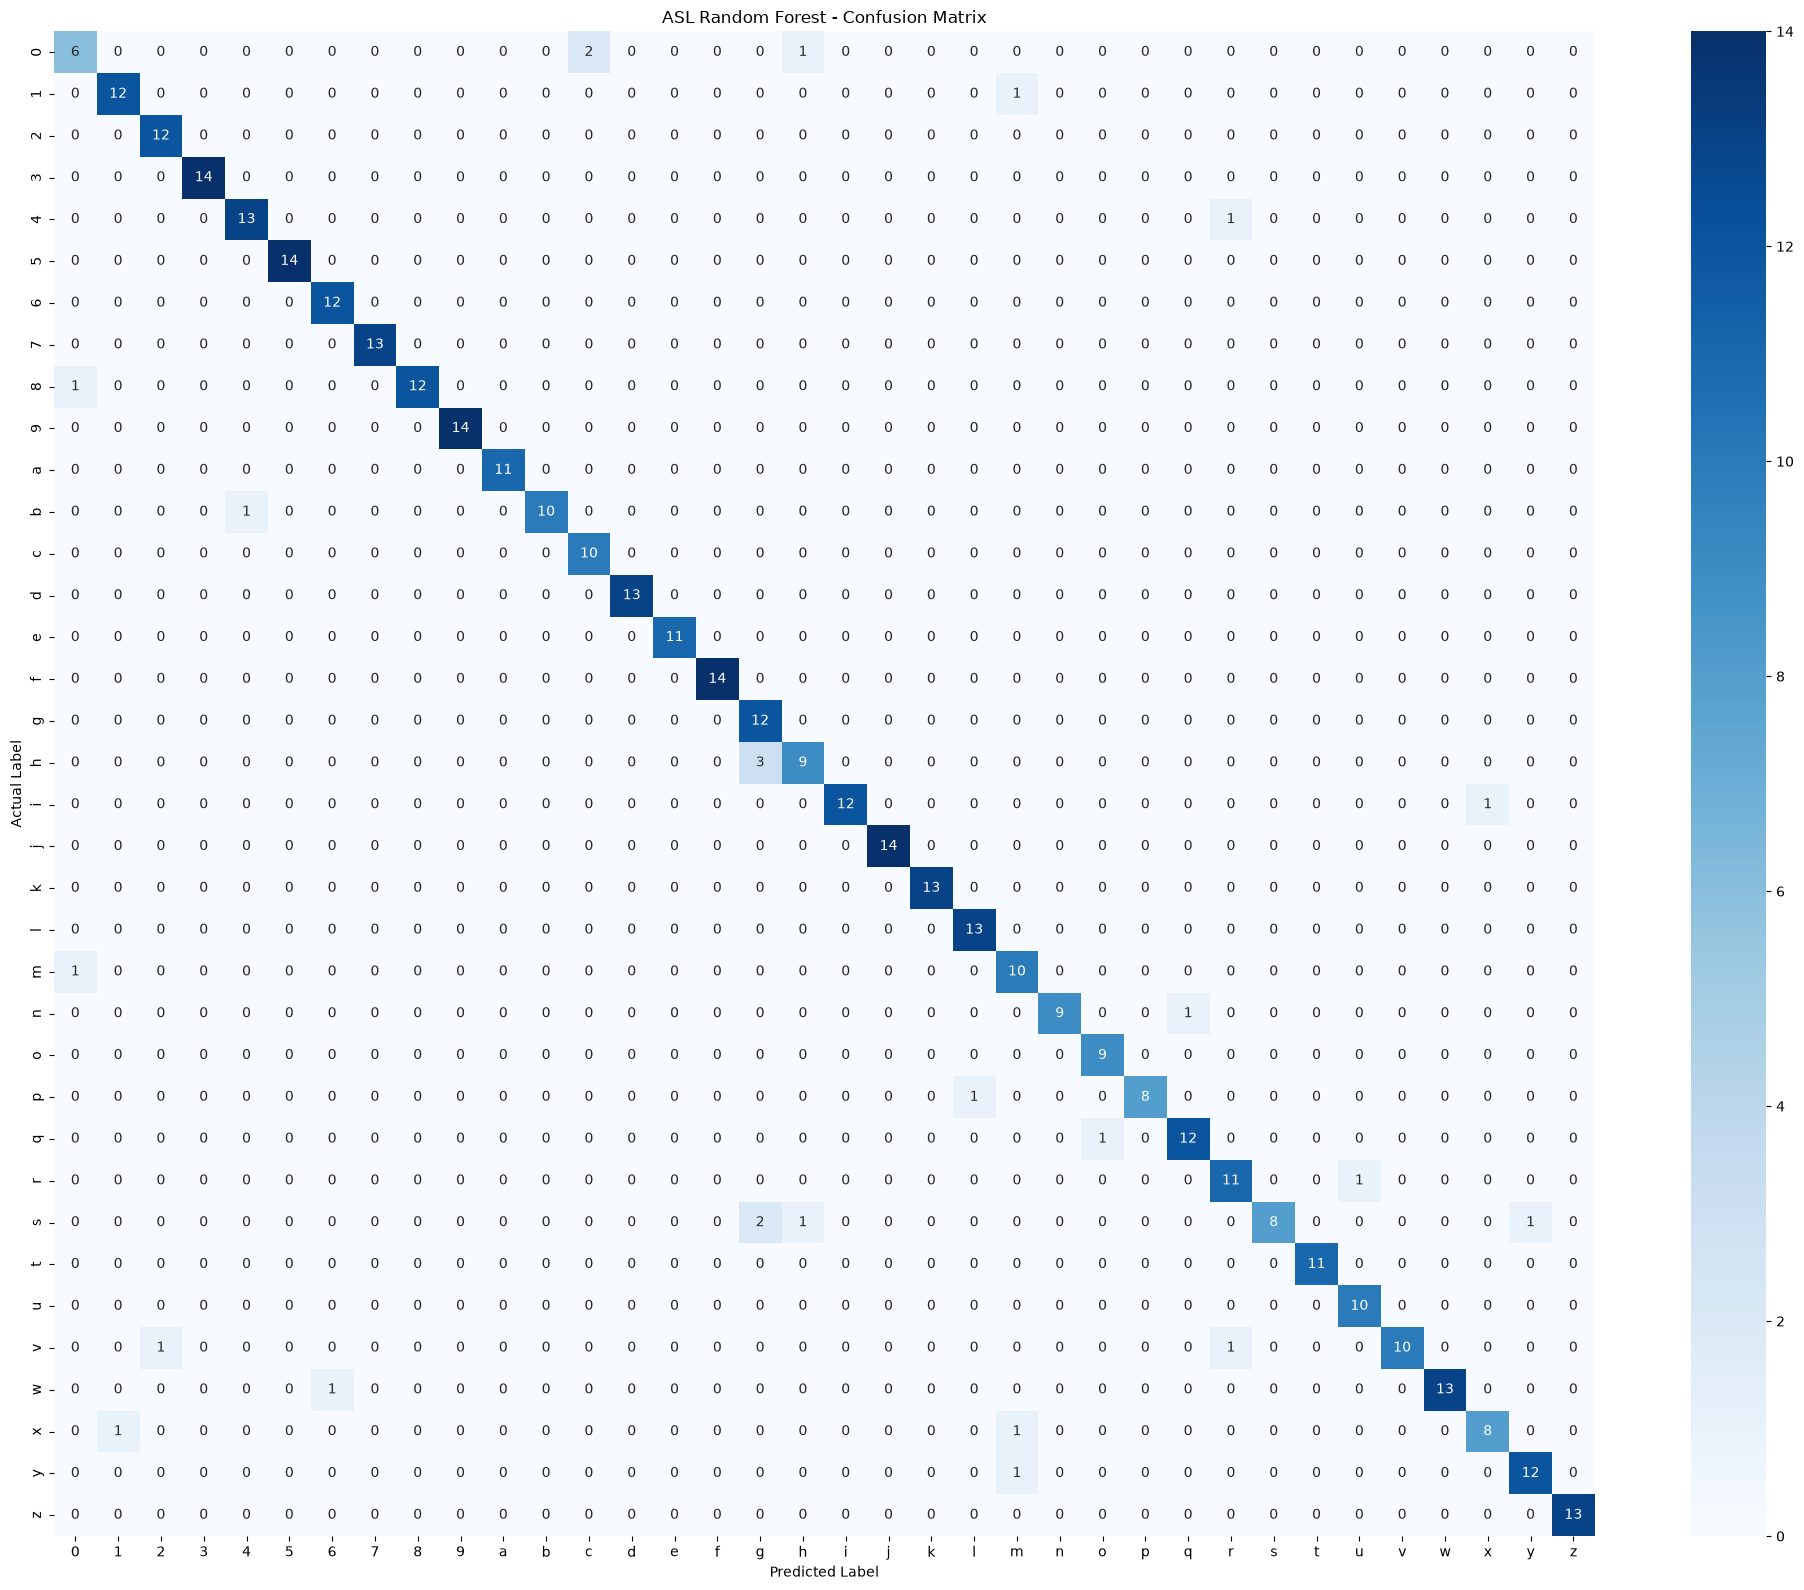

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=asl_model.classes_
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=asl_model.classes_,
    yticklabels=asl_model.classes_
)

plt.title("ASL Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [78]:
import joblib

MODEL_PATH = PROJECT_ROOT / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

asl_model_path = MODEL_PATH / "asl_random_forest.pkl"

joblib.dump(asl_model, asl_model_path)

print("ASL model saved successfully!")
print("Location:", asl_model_path)

ASL model saved successfully!
Location: c:\Users\admin\Desktop\SignBridge\models\asl_random_forest.pkl


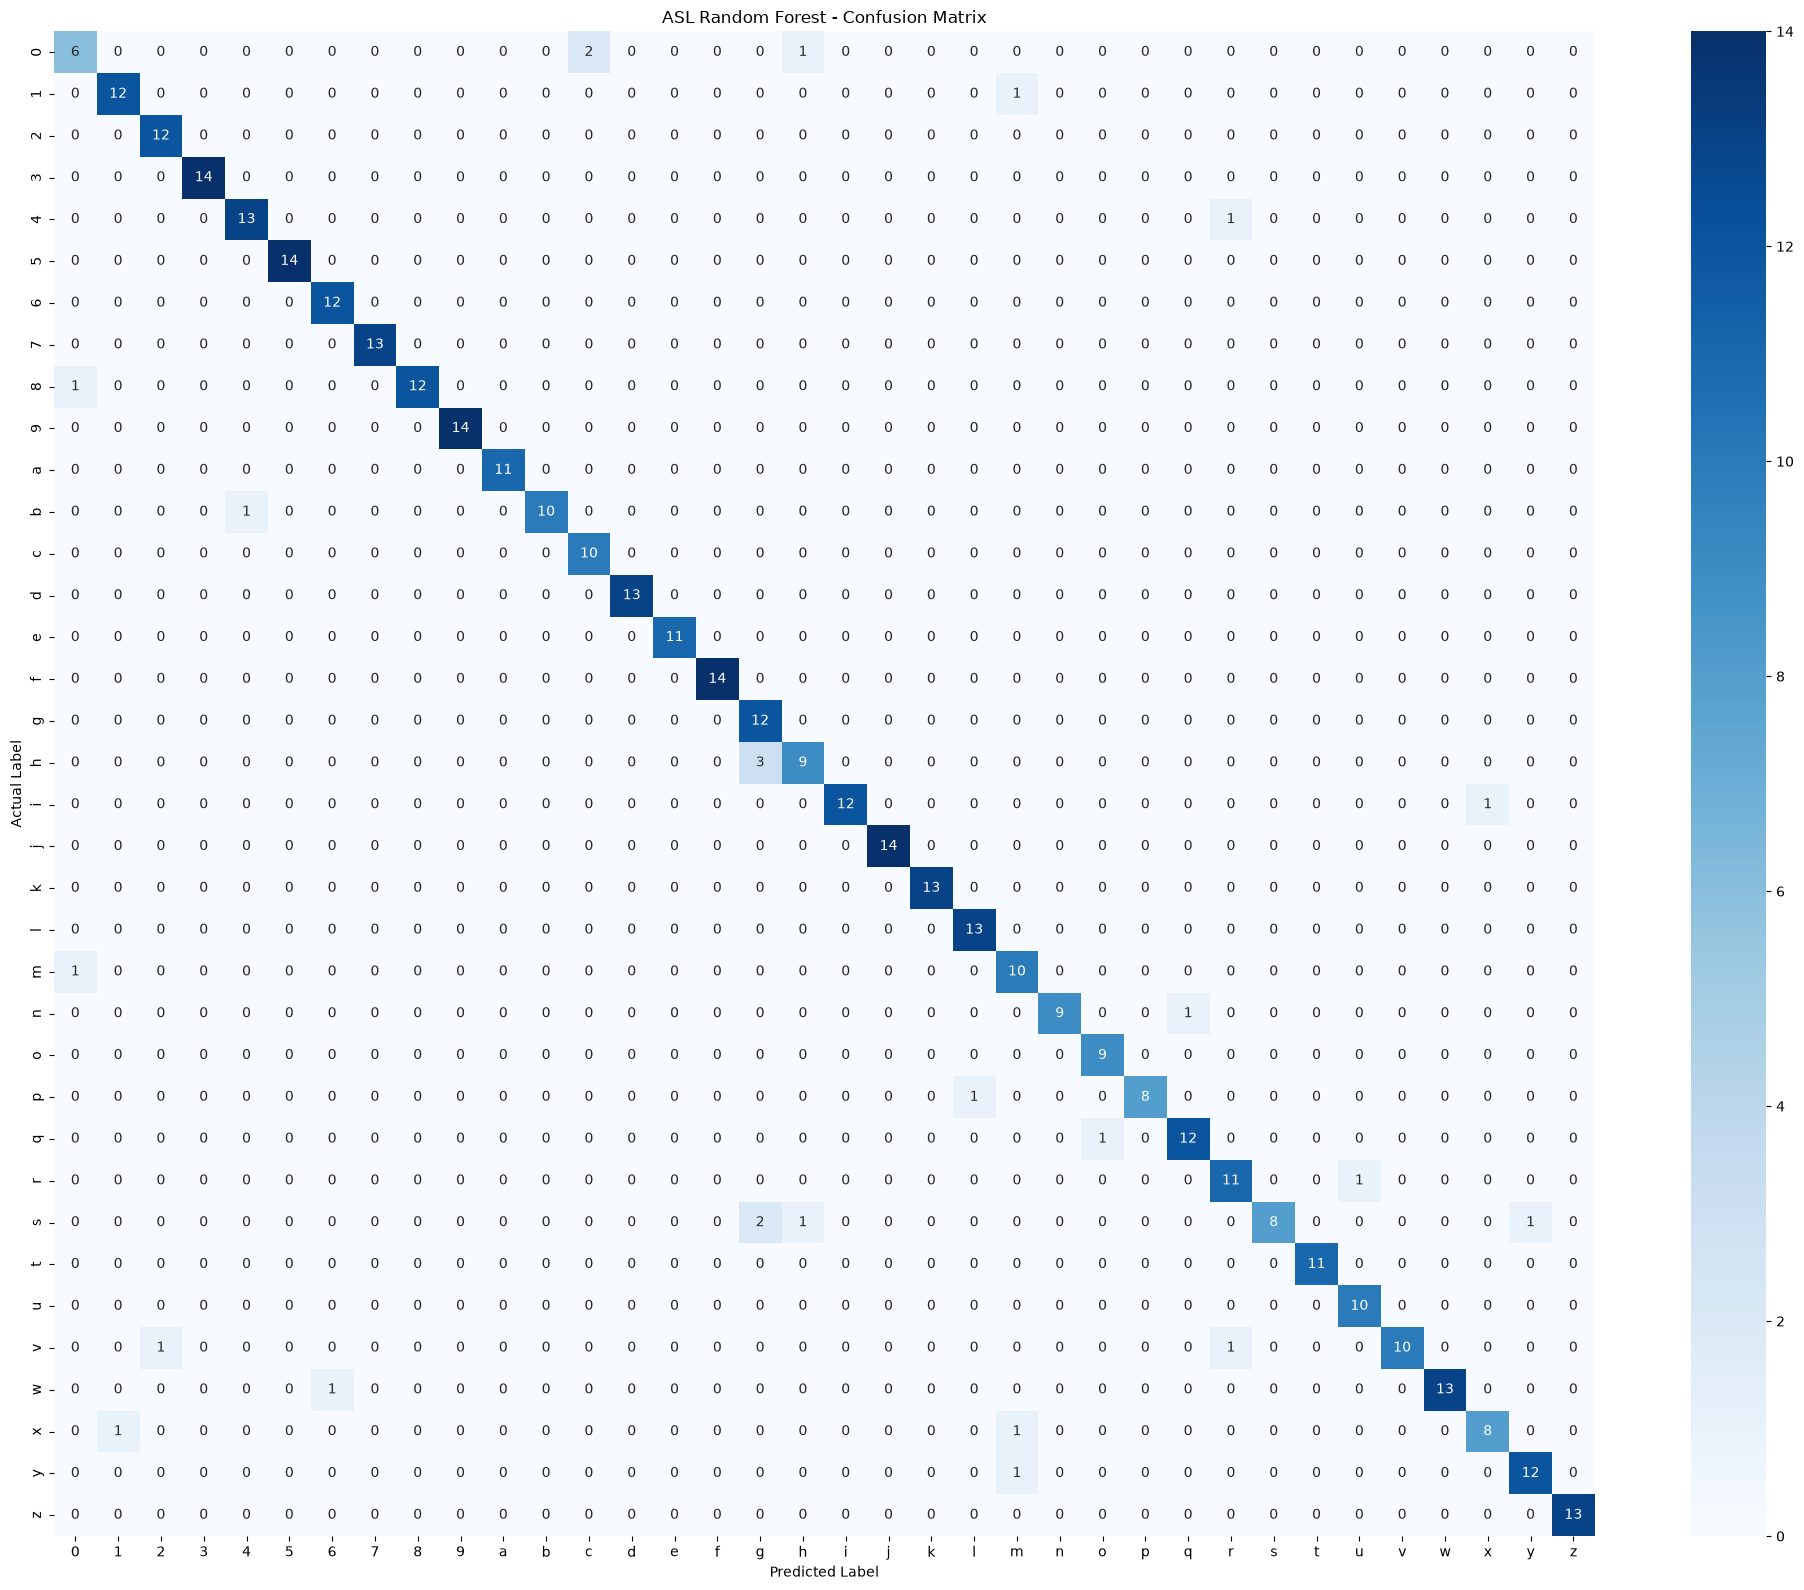

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=asl_model.classes_
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=asl_model.classes_,
    yticklabels=asl_model.classes_
)

plt.title("ASL Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [80]:
import joblib

MODEL_PATH = PROJECT_ROOT / "models"
MODEL_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(
    asl_model,
    MODEL_PATH / "asl_random_forest.pkl"
)

print("ASL model saved successfully!")

ASL model saved successfully!


In [81]:
import pandas as pd
from pathlib import Path

isl_csv_path = PROCESSED_PATH / "isl_landmarks.csv"

isl_df = pd.read_csv(isl_csv_path)

print("ISL dataset loaded!")
print("Dataset shape:", isl_df.shape)
print("Number of classes:", isl_df["label"].nunique())

print("\nClass distribution:")
print(isl_df["label"].value_counts().sort_index())

C:\Users\admin\AppData\Local\Temp\ipykernel_11176\2150424503.py:6: DtypeWarning: Columns (0: label) have mixed types. Specify dtype option on import or set low_memory=False.
  isl_df = pd.read_csv(isl_csv_path)


ISL dataset loaded!
Dataset shape: (41164, 65)
Number of classes: 36

Class distribution:


TypeError: '<' not supported between instances of 'str' and 'int'